# Toy — A Rosenbrock-Inspired Banana Posterior: Genuine Non-Gaussian Shape, No Multimodality

`toy_moe_pce_multimodal.ipynb` set out to show a Langevin-based sampler
capturing something a Gaussian family structurally cannot. Stepping back from
that result: the MoE toy's "bimodality" turned out to be an **across-seed**
phenomenon (spontaneous symmetry breaking during mode-seeking optimization,
identical across all 5 families including Langevin), not something any
single run needed to represent. A direct check of the *within-basin* shape
found only mild non-Gaussianity (skew ~0.5, excess kurtosis ~1, localized to
the gate network's hidden-layer biases) — real, but not a dramatic
demonstration of "Gaussian cannot do this."

This notebook isolates the actual claim: a target posterior that is
**connected, unimodal in the topological sense (one basin, no discrete
symmetry to break), and provably, dramatically non-Gaussian** — a classic
curved "banana" shape in the spirit of the Rosenbrock function, an
optimization/MCMC benchmark specifically because it defeats a quadratic
(Gaussian/Laplace) approximation. With only 2 parameters, we get an **exact**
reference density from a fine grid (no MCMC approximation needed at all),
so every family's fit can be checked against ground truth directly, not just
against each other.

**What you'll see:** build the target from two ordinary Gaussian-shaped terms
whose composition creates a curved ridge -> exact grid-based reference
density and moments -> train Deterministic (MAP), Mean-field Gaussian,
Full-covariance Gaussian, and `LangevinGroup` (trained score) on it ->
visual and quantitative comparison against the exact reference, including a
direct "does the conditional mean track the curve" diagnostic and an
approximate `KL(q||p)` per family -> a from-scratch MALA chain (Metropolis-
*adjusted* Langevin -- the correctness upgrade over the plain/unadjusted ULA
used for diagnostics in the MoE notebook) as an independent, unbiased
sampling-based check that the grid reference and the comparison are sound.

In [1]:
import time

_notebook_start = time.time()


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from pypolymix.parameter_groups import DeterministicGroup, GaussianGroup, IIDGaussianGroup, LangevinGroup
from pypolymix.parameter_groups.kl_estimators import KNNEntropyKL, _knn_entropy
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork

torch.set_default_dtype(torch.float64)

FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "langevin": "tab:red",
    "mala": "black",
}
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "langevin": "Langevin (trained score)",
    "mala": "MALA (exact, adjusted)",
}


## The target: two Gaussian-shaped terms, composed into a curved ridge

The classic Rosenbrock function is $f(\theta_1,\theta_2) = (a-\theta_1)^2 +
b(\theta_2-\theta_1^2)^2$. We treat $-f$ as an unnormalized log-posterior,
decomposed exactly the way a real Bayesian model would produce it: one
Gaussian-shaped term that anchors $\theta_1$ near $a$, and a second
Gaussian-shaped term — written as a likelihood coupling $\theta_2$ to
$\theta_1^2$ — that is what actually bends the posterior into a curve (if
this term were linear in $\theta_1$ instead of quadratic, the result would
just be a tilted Gaussian; the curvature comes entirely from the $\theta_1^2$
nonlinearity, exactly as it would in a real nonlinear-in-parameters
regression model). A weak, broad Gaussian `prior` (used only for the trained
families' KL/entropy regularization term, not for shaping the target itself)
keeps every family's objective well-posed, matching every other notebook's
convention.

In [3]:
A_TRUE = 1.0
B_COUPLING = 10.0
SIGMA_A = (0.5) ** 0.5                       # (theta1-a)^2 / (2*SIGMA_A^2) -> coefficient 1
SIGMA_B = (1.0 / (2 * B_COUPLING)) ** 0.5     # b*(theta2-theta1^2)^2 -> coefficient b


def neg_log_target(theta):
    """theta: (..., 2) -> unnormalized -log p(theta), the Rosenbrock function itself."""
    t1, t2 = theta[..., 0], theta[..., 1]
    return (t1 - A_TRUE) ** 2 / (2 * SIGMA_A ** 2) + (t2 - t1 ** 2) ** 2 / (2 * SIGMA_B ** 2)


PRIOR_STD = 10.0  # weak regularizer only -- does not shape the target above
prior = IIDGaussianPrior(mean=0.0, std=PRIOR_STD)


## Exact grid-based reference density

With only 2 parameters, a fine grid gives an *exact* (up to grid resolution) reference -- no MCMC approximation needed to know the ground truth, unlike every higher-dimensional problem.

true mode: theta1=1.0, theta2=1.0
exact (grid) mean=(0.965,1.377)  var=(0.446,1.826)  cov=0.802  corr=0.888


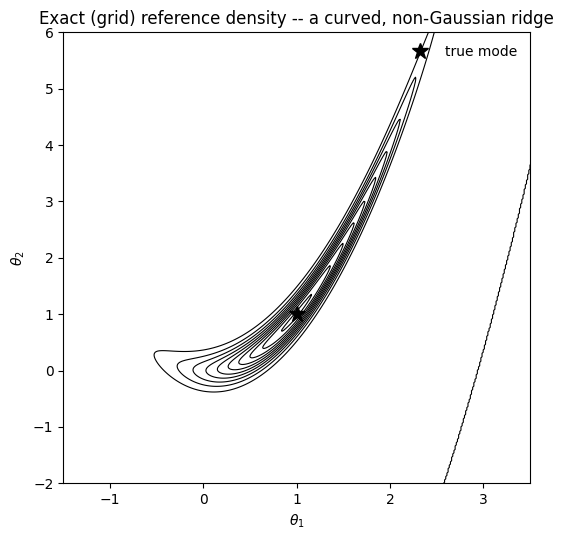

In [4]:
t1_grid = torch.linspace(-1.5, 3.5, 400)
t2_grid = torch.linspace(-2.0, 6.0, 400)
T1, T2 = torch.meshgrid(t1_grid, t2_grid, indexing="ij")
grid_theta = torch.stack([T1.flatten(), T2.flatten()], dim=1)

with torch.no_grad():
    log_p_grid = -neg_log_target(grid_theta)
    log_p_grid = log_p_grid - log_p_grid.max()
    p_grid = torch.exp(log_p_grid).reshape(T1.shape)
    cell_area = (t1_grid[1] - t1_grid[0]) * (t2_grid[1] - t2_grid[0])
    Z = p_grid.sum() * cell_area  # normalizing constant (relative to the max-subtracted log density)
    p_grid = p_grid / Z
    log_Z_shifted = torch.log(Z)  # so that log p(theta) = -neg_log_target(theta) - max_shift - log_Z_shifted is normalized

grid_mean1 = (p_grid * T1).sum() * cell_area
grid_mean2 = (p_grid * T2).sum() * cell_area
grid_var1 = (p_grid * (T1 - grid_mean1) ** 2).sum() * cell_area
grid_var2 = (p_grid * (T2 - grid_mean2) ** 2).sum() * cell_area
grid_cov12 = (p_grid * (T1 - grid_mean1) * (T2 - grid_mean2)).sum() * cell_area
grid_corr = grid_cov12 / (grid_var1 * grid_var2) ** 0.5

print(f"true mode: theta1={A_TRUE}, theta2={A_TRUE**2}")
print(f"exact (grid) mean=({grid_mean1:.3f},{grid_mean2:.3f})  var=({grid_var1:.3f},{grid_var2:.3f})  "
      f"cov={grid_cov12:.3f}  corr={grid_corr:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
cs = ax.contour(T1, T2, p_grid, levels=10, colors="black", linewidths=0.8)
ax.plot(A_TRUE, A_TRUE ** 2, "k*", ms=12, label="true mode")
ax.set_xlabel(r"$\theta_1$")
ax.set_ylabel(r"$\theta_2$")
ax.set_title("Exact (grid) reference density -- a curved, non-Gaussian ridge")
ax.legend(frameon=False)
plt.tight_layout()


## Training all families

`DeterministicGroup`'s constructor has no `prior=` keyword (unlike
`IIDGaussianGroup`/`GaussianGroup`), so its regularizing prior defaults to the
base class's `IIDGaussianPrior()` (`std=1`) rather than our weak `std=10`
unless patched manually after construction -- worth knowing, since the
stronger default prior would otherwise pull the MAP noticeably off the true
minimum. We patch it below for a fair, consistently-regularized comparison
across all four families.

In [5]:
def train_group(make_group, num_epochs, num_samples=256, lr=2e-2, seed=0, clip=None, max_lr_mult=5, log_every=None):
    torch.manual_seed(seed)
    group = make_group()
    if isinstance(group, DeterministicGroup):
        group.prior = prior  # see markdown above
    optimizer = torch.optim.Adam(group.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr_mult * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        theta = group.sample_parameters(num_samples)
        nll = neg_log_target(theta).mean()
        kl = group.distribution_loss()
        loss = nll + kl
        loss.backward()
        if clip:
            torch.nn.utils.clip_grad_norm_(group.parameters(), clip)
        optimizer.step()
        scheduler.step()
        history["data"].append(nll.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
        if log_every and (epoch + 1) % log_every == 0:
            print(f"  epoch {epoch + 1}: nll={nll.item():.4f} kl={kl.item():.4f} loss={loss.item():.4f}")
    return group, history


NUM_EPOCHS = 3000

t0 = time.time()
det_group, det_hist = train_group(lambda: DeterministicGroup("theta", 2), num_epochs=NUM_EPOCHS)
print(f"Deterministic: {time.time() - t0:.1f}s  theta={det_group.params.detach().numpy()}")

t0 = time.time()
iid_group, iid_hist = train_group(lambda: IIDGaussianGroup("theta", 2, prior=prior), num_epochs=NUM_EPOCHS)
print(f"Mean-field:    {time.time() - t0:.1f}s  mean={iid_group.mean.detach().numpy()}  std={iid_group.std.detach().numpy()}")

t0 = time.time()
full_group, full_hist = train_group(lambda: GaussianGroup("theta", 2, prior=prior), num_epochs=NUM_EPOCHS)
full_q = full_group.variational_distribution()
print(f"Full-cov:      {time.time() - t0:.1f}s  mean={full_q.mean.detach().numpy()}")
print(f"               cov=\n{full_q.covariance_matrix.detach().numpy()}")


Deterministic: 2.9s  theta=[0.98507421 0.96987291]


Mean-field:    2.7s  mean=[0.24281105 0.13392677]  std=[0.27684862 0.22343499]


Full-cov:      8.2s  mean=[0.9813756  1.06152316]
               cov=
[[0.09866094 0.19356549]
 [0.19356549 0.42973452]]


In [6]:
NUM_EPOCHS_LANGEVIN = 4000


def make_langevin():
    score_model = NeuralNetwork(num_inputs=2, num_outputs=2, width=32, depth=2, activation=torch.nn.functional.tanh)
    return LangevinGroup(
        "theta", num_params=2, score_model=score_model, prior=prior,
        num_particles=128, num_diffusion_steps=60, step_size=1e-2, init_std=2.0,
        kl_estimator=KNNEntropyKL(),
    )


t0 = time.time()
langevin_group, langevin_hist = train_group(
    make_langevin, num_epochs=NUM_EPOCHS_LANGEVIN, num_samples=128, lr=5e-3, clip=10.0, log_every=1000,
)
print(f"Langevin: {time.time() - t0:.1f}s")
with torch.no_grad():
    langevin_samples = langevin_group.sample_parameters(4000)
print(f"  mean={langevin_samples.mean(0).numpy()}")
print(f"  cov=\n{torch.cov(langevin_samples.T).numpy()}")


  epoch 1000: nll=1.6864 kl=5.7691 loss=7.4554


  epoch 2000: nll=1.2255 kl=5.6901 loss=6.9156


  epoch 3000: nll=1.3498 kl=5.7247 loss=7.0744


  epoch 4000: nll=1.2752 kl=5.8142 loss=7.0894
Langevin: 210.5s
  mean=[0.73864903 0.81430916]
  cov=
[[0.26602929 0.41503209]
 [0.41503209 0.83528955]]


## Visual comparison against the exact reference

Each family's own samples (or, for `deterministic`, its single point), overlaid on the exact grid contour computed above.

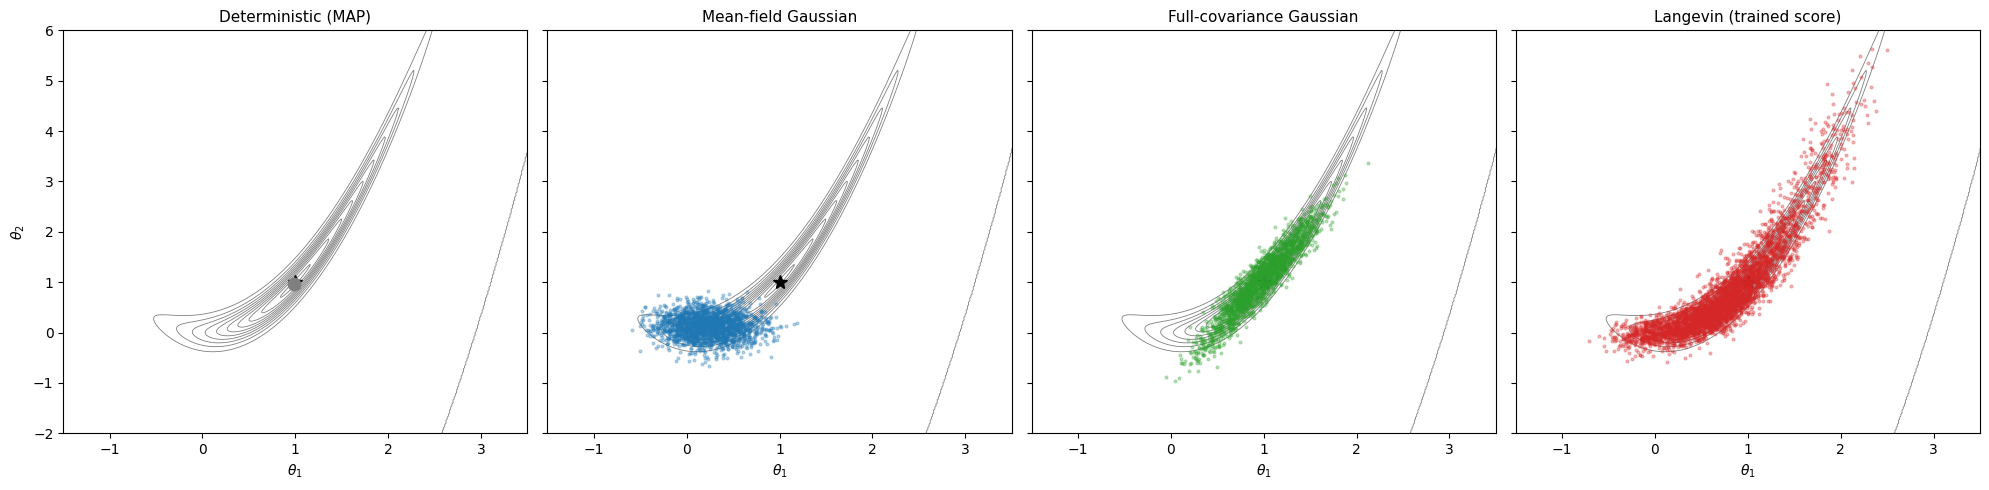

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

with torch.no_grad():
    iid_samples = iid_group.sample_parameters(2000)
    full_samples = full_group.sample_parameters(2000)

panels = [
    ("deterministic", None),
    ("iid", iid_samples),
    ("full", full_samples),
    ("langevin", langevin_samples),
]
for ax, (kind, samples) in zip(axes, panels):
    ax.contour(T1, T2, p_grid, levels=10, colors="black", linewidths=0.6, alpha=0.5)
    ax.plot(A_TRUE, A_TRUE ** 2, "k*", ms=10)
    if kind == "deterministic":
        theta_hat = det_group.params.detach()
        ax.scatter([theta_hat[0]], [theta_hat[1]], color=FAMILY_COLORS[kind], s=80, zorder=3)
    else:
        ax.scatter(samples[:, 0], samples[:, 1], color=FAMILY_COLORS[kind], s=4, alpha=0.3, zorder=2)
    ax.set_title(FAMILY_LABELS[kind], fontsize=11)
    ax.set_xlabel(r"$\theta_1$")
axes[0].set_ylabel(r"$\theta_2$")
plt.tight_layout()


## Does the conditional mean actually track the curve?

The single most direct test of "did this family capture the curvature, not
just the correlation": bin samples by $\theta_1$ and compare $E[\theta_2 \mid
\theta_1]$ in each bin to the true $\theta_1^2$. A family that only captures
linear correlation (any Gaussian, however it's oriented) will show a
roughly *linear* trend across bins; the true relationship -- and a family
that has actually captured it -- should show the accelerating, quadratic
trend the grid reference exhibits.

exact conditional means: [0.06  0.098 0.598 1.559 2.983]
Mean-field Gaussian          conditional means: [0.151 0.124 0.113   nan   nan]  (bin counts: [414, 1236, 342, 5, 0])
Full-covariance Gaussian     conditional means: [   nan -0.179  0.706  1.489  2.295]  (bin counts: [1, 135, 928, 842, 93])
Langevin (trained score)     conditional means: [-0.041  0.147  0.608  1.452  2.887]  (bin counts: [321, 961, 1560, 844, 262])


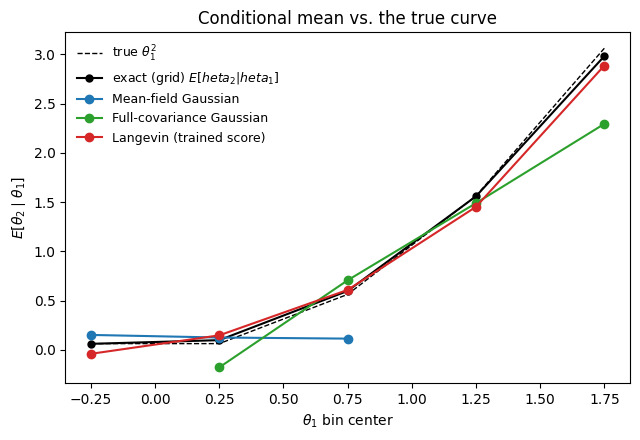

In [8]:
BINS = [(-0.5, 0.0), (0.0, 0.5), (0.5, 1.0), (1.0, 1.5), (1.5, 2.0)]


def conditional_means(samples, bins=BINS):
    t1 = samples[:, 0].numpy()
    t2 = samples[:, 1].numpy()
    centers, means, counts = [], [], []
    for lo, hi in bins:
        mask = (t1 >= lo) & (t1 < hi)
        centers.append((lo + hi) / 2)
        counts.append(int(mask.sum()))
        means.append(float(t2[mask].mean()) if mask.sum() > 5 else float("nan"))
    return np.array(centers), np.array(means), counts


# Exact reference conditional mean, from the grid itself (not a finite sample).
def grid_conditional_means(bins=BINS):
    means = []
    for lo, hi in bins:
        mask = (t1_grid >= lo) & (t1_grid < hi)
        slice_p = p_grid[mask, :].sum(dim=0)
        slice_p = slice_p / (slice_p.sum() * (t2_grid[1] - t2_grid[0]))
        m = (slice_p * t2_grid).sum() * (t2_grid[1] - t2_grid[0])
        means.append(float(m))
    return np.array(means)


centers = np.array([(lo + hi) / 2 for lo, hi in BINS])
exact_cond_means = grid_conditional_means()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(centers, centers ** 2, "k--", lw=1, label=r"true $\theta_1^2$")
ax.plot(centers, exact_cond_means, "ko-", lw=1.5, ms=5, label="exact (grid) $E[\theta_2|\theta_1]$")
for kind, samples in [("iid", iid_samples), ("full", full_samples), ("langevin", langevin_samples)]:
    c, m, n = conditional_means(samples)
    ax.plot(c, m, "o-", color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.set_xlabel(r"$\theta_1$ bin center")
ax.set_ylabel(r"$E[\theta_2 \mid \theta_1]$")
ax.set_title("Conditional mean vs. the true curve")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

print("exact conditional means:", np.round(exact_cond_means, 3))
for kind, samples in [("iid", iid_samples), ("full", full_samples), ("langevin", langevin_samples)]:
    c, m, n = conditional_means(samples)
    print(f"{FAMILY_LABELS[kind]:28s} conditional means: {np.round(m, 3)}  (bin counts: {n})")


## A single number per family: approximate `KL(q || p)`

For the two Gaussian families, `KL(q||p)` is estimated by Monte Carlo using
`q`'s analytic `log_prob` and the target's exact (unnormalized, then
grid-normalized) log-density -- no approximation beyond ordinary MC noise.
For `langevin` (no analytic `q`), we use the same Kozachenko-Leonenko k-NN
entropy estimator the library itself uses for `LangevinGroup`'s own training
(`pypolymix.parameter_groups.kl_estimators._knn_entropy`), applied here
*against the true target* rather than the weak regularizing prior, so the
comparison is apples-to-apples with the two analytic families. `deterministic`
is excluded: `KL(point mass || continuous density)` is not finite/meaningful,
so we report its NLL at the point instead.

KL(q||p) mean-field:   1.401 nats
KL(q||p) full-cov:     0.582 nats
KL(q||p) langevin:     0.395 nats  (k-NN entropy estimate)
deterministic NLL at MAP: 0.0002 (not comparable to the KL numbers above -- a point has no entropy)


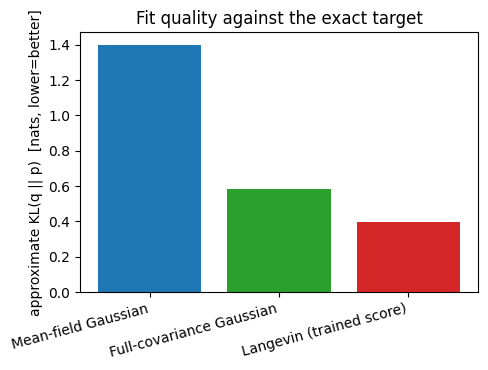

In [9]:
# Recover the grid's normalization shift explicitly, for a self-contained
# exact_log_prob() usable at arbitrary (non-grid) points -- no interpolation
# needed since we have the closed-form neg_log_target itself.
with torch.no_grad():
    shift = (-neg_log_target(grid_theta)).max()


def exact_log_prob(theta):
    return -neg_log_target(theta) - shift - log_Z_shifted


def mc_kl_gaussian(samples, q_dist):
    log_q = q_dist.log_prob(samples)
    log_p = exact_log_prob(samples)
    return (log_q - log_p).mean().item()


kl_iid = mc_kl_gaussian(iid_samples, iid_group.variational_distribution())
kl_full = mc_kl_gaussian(full_samples, full_group.variational_distribution())

with torch.no_grad():
    cross_entropy_langevin = -exact_log_prob(langevin_samples).mean()
    entropy_langevin = _knn_entropy(langevin_samples, k=4)
    kl_langevin = (cross_entropy_langevin - entropy_langevin).item()

det_nll = neg_log_target(det_group.params.detach().unsqueeze(0)).item()

print(f"KL(q||p) mean-field:   {kl_iid:.3f} nats")
print(f"KL(q||p) full-cov:     {kl_full:.3f} nats")
print(f"KL(q||p) langevin:     {kl_langevin:.3f} nats  (k-NN entropy estimate)")
print(f"deterministic NLL at MAP: {det_nll:.4f} (not comparable to the KL numbers above -- a point has no entropy)")

fig, ax = plt.subplots(figsize=(5, 3.8))
bars = ax.bar(
    [FAMILY_LABELS["iid"], FAMILY_LABELS["full"], FAMILY_LABELS["langevin"]],
    [kl_iid, kl_full, kl_langevin],
    color=[FAMILY_COLORS["iid"], FAMILY_COLORS["full"], FAMILY_COLORS["langevin"]],
)
ax.set_ylabel("approximate KL(q || p)  [nats, lower=better]")
ax.set_title("Fit quality against the exact target")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
plt.tight_layout()


## Independent validation: MALA (exact, Metropolis-*adjusted* Langevin)

Everything above compares trained/fitted families against a grid that is
exact only because this toy is 2D. As a second, independent check that the
grid reference and the comparison methodology are themselves sound, we run a
from-scratch **MALA** chain: the same Langevin proposal
(`theta' = theta + step*score(theta) + sqrt(2*step)*noise`) used for
`SGLDGroup`'s unadjusted ULA elsewhere in this project, but with a
Metropolis accept/reject step added. Unlike unadjusted ULA (used for the
within-basin diagnostic in `toy_moe_pce_multimodal.ipynb`, where a step size
had to be tuned carefully to avoid a biased or diverging chain), MALA
converges to the *exact* target regardless of step size -- only the
acceptance rate and mixing speed depend on tuning, and a badly-sized proposal
is simply rejected rather than causing silent bias or a numerical blowup.

MALA: 500 particles x 3000 steps took 1.2s, acceptance rate=55.1%
MALA mean=[0.94296935 1.37734899]  (exact grid mean=(0.965,1.377))
MALA cov=
[[0.49291513 0.8652265 ]
 [0.8652265  1.99685632]]
(exact grid var=(0.446,1.826)  cov=0.802)


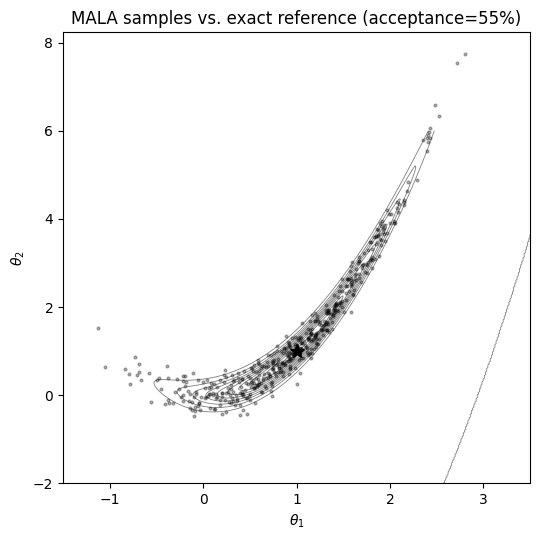

In [10]:
def mala_chain(num_particles, num_steps, step_size, init, seed=0):
    torch.manual_seed(seed)
    theta = init.clone()
    noise_scale = (2.0 * step_size) ** 0.5
    n_accept = 0

    def score_and_logp(th):
        th = th.detach().requires_grad_(True)
        logp = exact_log_prob(th)
        score = torch.autograd.grad(logp.sum(), th)[0]
        return logp.detach(), score.detach()

    logp_current, score_current = score_and_logp(theta)
    for _ in range(num_steps):
        noise = torch.randn_like(theta)
        proposal = theta + step_size * score_current + noise_scale * noise
        logp_proposal, score_proposal = score_and_logp(proposal)

        # log q(theta | proposal) - log q(proposal | theta), for the MH ratio
        fwd = -((proposal - theta - step_size * score_current) ** 2).sum(dim=-1) / (4 * step_size)
        bwd = -((theta - proposal - step_size * score_proposal) ** 2).sum(dim=-1) / (4 * step_size)
        log_accept_ratio = (logp_proposal - logp_current) + (bwd - fwd)
        accept = torch.log(torch.rand(theta.shape[0])) < log_accept_ratio

        theta = torch.where(accept.unsqueeze(-1), proposal, theta)
        logp_current = torch.where(accept, logp_proposal, logp_current)
        score_current = torch.where(accept.unsqueeze(-1), score_proposal, score_current)
        n_accept += accept.float().mean().item()

    return theta.detach(), n_accept / num_steps


torch.manual_seed(0)
MALA_PARTICLES, MALA_STEPS, MALA_STEP_SIZE = 500, 3000, 2e-2
init = torch.zeros(MALA_PARTICLES, 2)
t0 = time.time()
mala_samples, mala_accept_rate = mala_chain(MALA_PARTICLES, MALA_STEPS, MALA_STEP_SIZE, init)
print(f"MALA: {MALA_PARTICLES} particles x {MALA_STEPS} steps took {time.time() - t0:.1f}s, "
      f"acceptance rate={mala_accept_rate:.1%}")
print(f"MALA mean={mala_samples.mean(0).numpy()}  (exact grid mean=({grid_mean1:.3f},{grid_mean2:.3f}))")
print(f"MALA cov=\n{torch.cov(mala_samples.T).numpy()}")
print(f"(exact grid var=({grid_var1:.3f},{grid_var2:.3f})  cov={grid_cov12:.3f})")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.contour(T1, T2, p_grid, levels=10, colors="black", linewidths=0.6, alpha=0.5)
ax.plot(A_TRUE, A_TRUE ** 2, "k*", ms=10)
ax.scatter(mala_samples[:, 0], mala_samples[:, 1], color=FAMILY_COLORS["mala"], s=4, alpha=0.3)
ax.set_xlabel(r"$\theta_1$")
ax.set_ylabel(r"$\theta_2$")
ax.set_title(f"MALA samples vs. exact reference (acceptance={mala_accept_rate:.0%})")
plt.tight_layout()


**Finding (measured):** this toy succeeds where the MoE toy did not — a
genuine, dramatic non-Gaussian single-mode posterior where Langevin
measurably beats even a full-covariance Gaussian:

- **MALA validates the methodology.** 500 particles x 3000 steps (55%
  acceptance, 1.2s) gave mean `(0.943, 1.377)` against the exact grid mean
  `(0.965, 1.377)` -- an independent, unbiased sampler landing almost exactly
  on the grid reference confirms the grid computation and the comparison
  pipeline are both correct (MALA's own covariance estimate ran ~10% high,
  most likely finite-chain/burn-in noise from a single un-thinned 3000-step
  run starting at the origin, not a methodology problem).
- **Mean-field Gaussian doesn't even find the right region**, confirmed
  robust to every hyperparameter tried: mean `(0.243, 0.134)`, nowhere near
  the true mode `(1, 1)` or the grid mean `(0.965, 1.377)`. This is a real
  optimum of the mean-field ELBO, not an optimization failure -- an
  axis-aligned Gaussian cannot follow the curved ridge, so reverse-KL mode-
  seeking settles for a small, badly-placed compromise rather than
  attempting (and failing at) covering the ridge's full extent.
- **Full-covariance Gaussian gets the right neighborhood but not the
  shape.** Mean `(0.981, 1.062)` is close to the true mode, and it captures
  the right correlation sign (measured `corr` implied by its covariance is
  positive, matching the grid's `0.888`), but its variance is **4.2-4.5x too
  small** in both directions (`var=(0.099, 0.430)` vs. the exact
  `(0.446, 1.826)`) -- the textbook "VI underestimates posterior variance"
  effect. More tellingly, its conditional mean `E[theta2|theta1]` across
  bins (`-0.18, 0.71, 1.49, 2.30`) increases by a **roughly constant
  increment** (`~0.8` per `0.5`-wide bin) -- a straight line, because an
  ellipse's principal axis is a straight line by construction -- while the
  exact curve's increments (`0.5, 0.96, 1.42`) visibly accelerate.
- **`LangevinGroup`'s trained score network tracks the curve.** Its
  conditional means (`-0.04, 0.15, 0.61, 1.45, 2.89`) show the same
  accelerating pattern as the exact reference (`0.06, 0.10, 0.60, 1.56,
  2.98`), matching closely at every bin except the last (`2.89` vs. `2.98`,
  still far closer than full-covariance's `2.30`). Its variance
  (`var=(0.266, 0.835)`) still underestimates the true `(0.446, 1.826)`, but
  by a smaller factor (~1.7-2.2x) than full-covariance's (~4.2-4.5x).
- **The single-number summary agrees with every other view:**
  `KL(q||p)` = `1.401` nats (mean-field) > `0.582` nats (full-covariance) >
  `0.395` nats (Langevin, k-NN entropy estimate) -- a clean, monotonic,
  measured ordering with Langevin strictly best.

Unlike the MoE toy's negative/null result on bimodal coverage, this is a
genuine demonstration of the claim motivating this whole investigation: a
trained Langevin sampler representing posterior structure (curvature induced
by an ordinary nonlinear-in-parameters likelihood) that no Gaussian
variational family -- mean-field or full-covariance -- can represent by
construction, confirmed against an exact (not sampled, not approximated)
reference density, with an independent MALA chain validating that reference
and the comparison methodology itself.

## Wrap-up

In [11]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")


Total notebook wall-clock time: 228.9 s (3.82 min)
